# GridLeak AI
## 01 — Veri tanıtımı ve keşifsel veri analizi

Bu defter veri yapısını, eksikleri ve tüketim davranışlarını inceler. Model eğitmez.
Hücreleri yukarıdan aşağıya çalıştırın. Ham CSV değişmez; grafikler `reports/figures` içine kaydedilir.
Bu ilk keşif tüm veri üzerinde yapıldı; bu nedenle sonraki testin keşiften tamamen bağımsız olmadığı raporda belirtilmelidir.


### 1. Amaç ve veri kaynağı

Amaç, tüketim örüntülerinden kaçak etiketini tahmin etmeye ve saha incelemesini önceliklendirmeye yardımcı olmaktır.
Kaynak: https://www.kaggle.com/datasets/chabdullah31222/sgcc-electricity-theft-detection-dataset

`CONS_NO` kimliktir; `FLAG` hazır hedef etikettir (0: kaçak olmayan, 1: kaçak etiketli).
Kimlik ve FLAG modelin tüketim girdileri değildir. Etiketlerin denetim yöntemi, tüketim birimi ve özgün kullanım koşulları CSV'den doğrulanamaz; kaynak belgesiyle ayrıca teyit edilmelidir.


In [1]:
# Dosya ve klasör yollarıyla çalışmamızı sağlar.
from pathlib import Path

# Tablo şeklindeki verileri okumak ve incelemek için kullanılır.
import pandas as pd

# Masaüstündeki proje klasörümüz.
# Notebook hangi bilgisayarda açılırsa açılsın proje kökünü bulur.
proje_klasoru = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "raw" / "data.csv").is_file()),
    None
)
if proje_klasoru is None:
    raise FileNotFoundError("Notebook'u GridLeakAI/ai/notebooks içinden açın.")

# Orijinal veri dosyamızın konumu.
veri_yolu = proje_klasoru / "data" / "raw" / "data.csv"

print("Veri dosyasının konumu:", veri_yolu)
print("Dosya bulundu mu?:", veri_yolu.is_file())

Veri dosyasının konumu: C:\Users\kadir\Desktop\GridLeakAI\data\raw\data.csv
Dosya bulundu mu?: True


In [2]:
from IPython.display import display
import matplotlib.pyplot as plt
figur_klasoru = proje_klasoru / "reports" / "figures"
figur_klasoru.mkdir(parents=True, exist_ok=True)

### 2. Dosyayı okuma ve boyutlar

In [3]:
# CSV dosyasını okuyup df adlı tabloya alıyoruz.
df = pd.read_csv(veri_yolu, dtype={"CONS_NO": str})

# Tablonun satır ve sütun sayısını gösteriyoruz.
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])

# İlk 10 sütunun adını gösteriyoruz.
print("İlk 10 sütun:", df.columns[:10].tolist())

# İlk 5 satırın ilk 8 sütununu gösteriyoruz.
df.iloc[:5, :8]

Satır sayısı: 42372
Sütun sayısı: 1036
İlk 10 sütun: ['CONS_NO', 'FLAG', '2014/1/1', '2014/1/10', '2014/1/11', '2014/1/12', '2014/1/13', '2014/1/14', '2014/1/15', '2014/1/16']


,CONS_NO,FLAG,2014/1/1,2014/1/10,2014/1/11,2014/1/12,2014/1/13,2014/1/14
0,0387DD8A07E07FDA6271170F86AD9151,1,NaN,NaN,NaN,NaN,NaN,NaN
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1,NaN,NaN,NaN,NaN,NaN,NaN
2,4B75AC4F2D8434CFF62DB64D0BB43103,1,NaN,NaN,NaN,NaN,NaN,NaN
3,B32AC8CC6D5D805AC053557AB05F5343,1,NaN,NaN,NaN,NaN,NaN,NaN
4,EDFC78B07BA2908B3395C4EB2304665E,1,2.9,3.42,3.81,4.58,3.56,4.25


### 3. Abone kimliği ve hedef etiket kontrolü

In [4]:
# Abone kimliklerinde eksik veya tekrar eden kayıt var mı?
print("Eksik abone kimliği:", df["CONS_NO"].isna().sum())
print("Benzersiz abone sayısı:", df["CONS_NO"].nunique())
print("Tekrarlanan abone kimliği:", df["CONS_NO"].duplicated().sum())

# Hedef değişkende hangi etiketlerden kaç tane var?
print("\nFLAG etiketlerinin dağılımı:")
print(df["FLAG"].value_counts(dropna=False))

# Etiketlerin tüm kayıtlar içindeki yüzdesi.
print("\nFLAG etiketlerinin yüzdesi:")
print(
    df["FLAG"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Eksik abone kimliği: 0
Benzersiz abone sayısı: 42372
Tekrarlanan abone kimliği: 0

FLAG etiketlerinin dağılımı:
FLAG
0    38757
1     3615
Name: count, dtype: int64

FLAG etiketlerinin yüzdesi:
FLAG
0    91.47
1     8.53
Name: proportion, dtype: float64


#### Sınıf dağılımı grafiği
Sayım grafiği, sınıf dengesizliğini gösterir; model başarısı değildir.

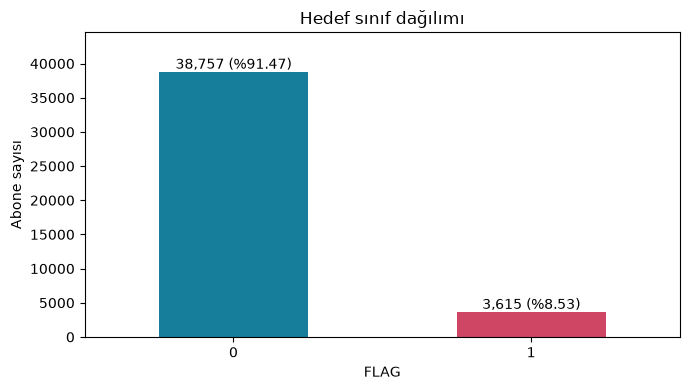

In [5]:
sayilar = df["FLAG"].value_counts().sort_index()
ax = sayilar.plot.bar(color=["#167D9A", "#CF4665"], rot=0, figsize=(7, 4))
ax.set(xlabel="FLAG", ylabel="Abone sayısı", title="Hedef sınıf dağılımı")
for i, sayi in enumerate(sayilar):
    ax.text(i, sayi, f"{sayi:,} (%{100*sayi/len(df):.2f})", ha="center", va="bottom")
ax.set_ylim(0, sayilar.max()*1.15)
plt.tight_layout()
plt.savefig(figur_klasoru / "01_sinif_dagilimi.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Eksik, sıfır ve negatif tüketim değerleri

In [6]:
# Kimlik ve hedef sütunlarını çıkarıp tüketim alanlarını ayırıyoruz.
tuketim = df.drop(columns=["CONS_NO", "FLAG"])

# Sütunların hangi veri türlerinde okunduğunu kontrol ediyoruz.
print("Tüketim sütunlarının veri türleri:")
print(tuketim.dtypes.value_counts())

# Sayısal olmayan tüketim sütunları varsa isimlerini gösteriyoruz.
sayisal_olmayan = tuketim.select_dtypes(exclude="number").columns
print("\nSayısal olmayan sütunlar:", sayisal_olmayan.tolist())

# Tüm tüketim tablosundaki eksik hücreleri sayıyoruz.
eksik_sayisi = tuketim.isna().sum().sum()
toplam_hucre = tuketim.size

print("\nToplam tüketim hücresi:", toplam_hucre)
print("Eksik tüketim hücresi:", eksik_sayisi)
print("Eksik veri yüzdesi:", round(100 * eksik_sayisi / toplam_hucre, 2))

# En az bir tüketim kaydı eksik olan aboneleri sayıyoruz.
print(
    "En az bir eksik kaydı olan abone:",
    tuketim.isna().any(axis=1).sum()
)

# Sayısal sütunlarda sıfır ve negatif değerleri kontrol ediyoruz.
sayisal_tuketim = tuketim.select_dtypes(include="number")

print("Sıfır tüketim hücresi:", sayisal_tuketim.eq(0).sum().sum())
print("Negatif tüketim hücresi:", sayisal_tuketim.lt(0).sum().sum())

Tüketim sütunlarının veri türleri:
float64    1034
Name: count, dtype: int64

Sayısal olmayan sütunlar: []

Toplam tüketim hücresi: 43812648
Eksik tüketim hücresi: 11233528
Eksik veri yüzdesi: 25.64
En az bir eksik kaydı olan abone: 42372
Sıfır tüketim hücresi: 5788603
Negatif tüketim hücresi: 0


### 5. Abone başına eksiklik

In [7]:
# Her abonenin kaç günlük tüketim kaydı eksik?
abone_eksik_gun = tuketim.isna().sum(axis=1)

# Eksik gün sayısını yüzdeye çeviriyoruz.
abone_eksik_yuzde = (
    abone_eksik_gun / tuketim.shape[1] * 100
)

# Aboneler arasındaki eksik veri durumunu özetliyoruz.
print("En düşük eksik oranı (%):", round(abone_eksik_yuzde.min(), 2))
print("Ortanca eksik oranı (%):", round(abone_eksik_yuzde.median(), 2))
print("En yüksek eksik oranı (%):", round(abone_eksik_yuzde.max(), 2))

print(
    "Kayıtlarının yarısından fazlası eksik olan abone:",
    (abone_eksik_yuzde > 50).sum()
)

En düşük eksik oranı (%): 0.1
Ortanca eksik oranı (%): 10.64
En yüksek eksik oranı (%): 100.0
Kayıtlarının yarısından fazlası eksik olan abone: 11184


### 6. Eksiklik dağılımı grafiği

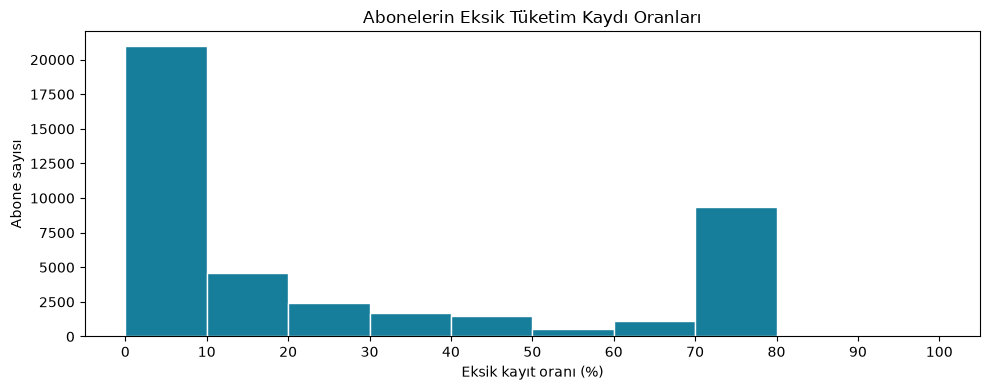

In [8]:
# Grafik çizmek için kullanacağımız kütüphane.
import matplotlib.pyplot as plt

# Grafiğin genişliğini ve yüksekliğini belirliyoruz.
plt.figure(figsize=(10, 4))

# Aboneleri eksik veri oranlarına göre gruplandırıp sayıyoruz.
plt.hist(
    abone_eksik_yuzde,
    bins=range(0, 101, 10),
    color="#167D9A",
    edgecolor="white"
)

plt.title("Abonelerin Eksik Tüketim Kaydı Oranları")
plt.xlabel("Eksik kayıt oranı (%)")
plt.ylabel("Abone sayısı")
plt.xticks(range(0, 101, 10))

plt.tight_layout()
plt.savefig(figur_klasoru / "01_eksiklik_histogrami.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Yüksek eksiklik grubunun sınıfları

In [9]:
# Eksik kayıt oranı %70 dahil, %80 hariç olan aboneleri belirliyoruz.
cok_eksik_grup = (
    (abone_eksik_yuzde >= 70)
    & (abone_eksik_yuzde < 80)
)

# Her sınıftaki toplam abone sayısı.
sinif_toplam = df["FLAG"].value_counts()

# Çok eksik grubun içindeki sınıf sayıları.
grup_sayilari = df.loc[cok_eksik_grup, "FLAG"].value_counts()

# Sonuçları tek tabloda birleştiriyoruz.
karsilastirma = pd.DataFrame({
    "Toplam abone": sinif_toplam,
    "Eksikliği %70–80 olan abone": grup_sayilari
}).fillna(0).astype(int)

# Her sınıfın yüzde kaçı bu grupta?
karsilastirma["Sınıfın bu gruptaki oranı (%)"] = (
    karsilastirma["Eksikliği %70–80 olan abone"]
    / karsilastirma["Toplam abone"]
    * 100
).round(2)

karsilastirma.sort_index()

,Toplam abone,Eksikliği %70–80 olan abone,Sınıfın bu gruptaki oranı (%)
FLAG,,,
0,38757,8442,21.78
1,3615,881,24.37


### 8. Tarihleri sıralama

In [10]:
# Tüketim sütunlarının adlarını gerçek tarihlere dönüştürüyoruz.
tarihler = pd.to_datetime(
    tuketim.columns,
    format="%Y/%m/%d"
)

# Tarihleri eskiden yeniye sıralayan konumları buluyoruz.
tarih_sirasi = tarihler.argsort()

# Tüketim sütunlarını bu sıraya göre ayrı bir tabloya alıyoruz.
tuketim_sirali = tuketim.iloc[:, tarih_sirasi].copy()

# Sütun adlarını tarih biçiminde yazıyoruz.
tuketim_sirali.columns = tarihler[tarih_sirasi]

print("İlk tarih:", tuketim_sirali.columns.min().date())
print("Son tarih:", tuketim_sirali.columns.max().date())
print("Tarih sütunu sayısı:", tuketim_sirali.shape[1])


İlk tarih: 2014-01-01
Son tarih: 2016-10-31
Tarih sütunu sayısı: 1034


### 9. Takvimde eksik tarih kontrolü

In [11]:
# İlk ve son tarih arasındaki bütün takvim günlerini oluşturuyoruz.
beklenen_tarihler = pd.date_range(
    start=tuketim_sirali.columns.min(),
    end=tuketim_sirali.columns.max(),
    freq="D"
)

# Takvimde olup dosyada sütunu bulunmayan tarihleri buluyoruz.
eksik_tarih_sutunlari = beklenen_tarihler.difference(
    tuketim_sirali.columns
)

print("Takvimde beklenen gün sayısı:", len(beklenen_tarihler))
print("Dosyadaki tarih sütunu sayısı:", tuketim_sirali.shape[1])

print("\nDosyada sütunu bulunmayan tarihler:")
print(eksik_tarih_sutunlari.strftime("%Y-%m-%d").tolist())

print(
    "\nTekrarlanan tarih sütunu sayısı:",
    tuketim_sirali.columns.duplicated().sum()
)

Takvimde beklenen gün sayısı: 1035
Dosyadaki tarih sütunu sayısı: 1034

Dosyada sütunu bulunmayan tarihler:
['2016-09-18']

Tekrarlanan tarih sütunu sayısı: 0


### 10. Beş örnekte kayıt düzeni

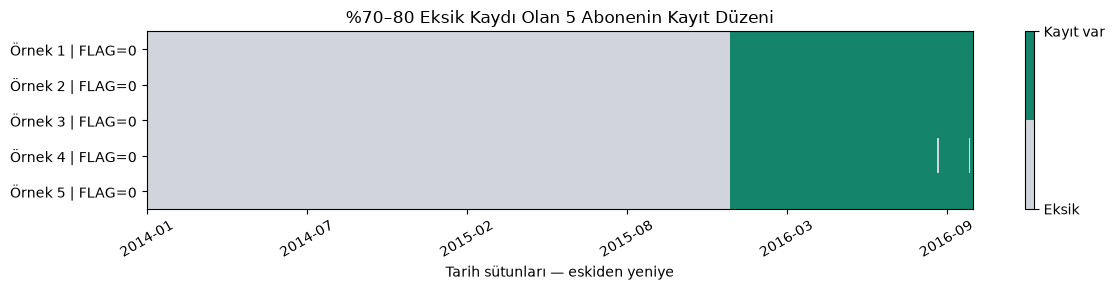

In [12]:
# %70–80 eksik kaydı olan abonelerden rastgele 5 örnek seçiyoruz.
ornekler = tuketim_sirali.loc[cok_eksik_grup].sample(
    n=5,
    random_state=42
)

# Her gün için kayıt varsa 1, eksikse 0 oluşturuyoruz.
kayit_durumu = ornekler.notna().astype(int)

# Gri: eksik kayıt, yeşil: kayıt var.
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(12, 3))

grafik = ax.imshow(
    kayit_durumu,
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap(["#D1D5DB", "#14856B"]),
    vmin=0,
    vmax=1
)

# Tarih etiketlerini yaklaşık 200 sütunda bir gösteriyoruz.
konumlar = list(range(0, kayit_durumu.shape[1], 200))

ax.set_xticks(konumlar)
ax.set_xticklabels(
    kayit_durumu.columns[konumlar].strftime("%Y-%m"),
    rotation=30
)

ax.set_yticks(range(len(ornekler)))
ax.set_yticklabels([
    f"Örnek {i + 1} | FLAG={df.loc[indeks, 'FLAG']}"
    for i, indeks in enumerate(ornekler.index)
])

ax.set_title("%70–80 Eksik Kaydı Olan 5 Abonenin Kayıt Düzeni")
ax.set_xlabel("Tarih sütunları — eskiden yeniye")

renk_cubugu = fig.colorbar(grafik, ax=ax, ticks=[0, 1])
renk_cubugu.ax.set_yticklabels(["Eksik", "Kayıt var"])

plt.tight_layout()
plt.savefig(figur_klasoru / "01_kayit_haritasi.png", dpi=150, bbox_inches="tight")
plt.show()

### 11. İlk dolu kayıt ayı

İncelenen abone sayısı: 9323

İlk dolu kaydın başladığı ay ve abone sayısı:
2014-01      19
2014-02       2
2014-03       2
2014-04       1
2014-05       2
2014-07       1
2014-08       7
2014-09       3
2016-01    9244
2016-02      11
2016-03      29
2016-04       2
Freq: M, Name: count, dtype: int64


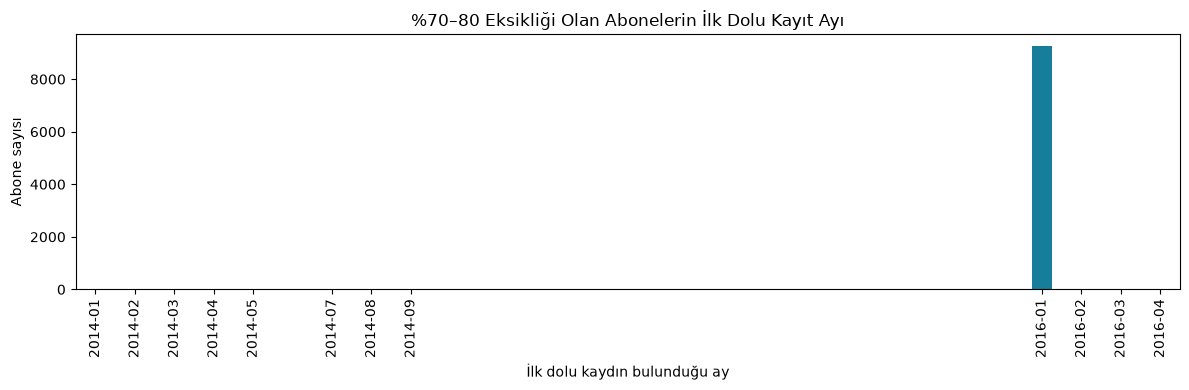

In [13]:
# %70–80 eksikliği olan bütün abonelerin kayıtlarını alıyoruz.
grup = tuketim_sirali.loc[cok_eksik_grup]

# Her abonenin ilk dolu kaydının tarihini buluyoruz.
ilk_kayit_tarihi = grup.apply(
    lambda satir: satir.first_valid_index(),
    axis=1
)

# Tarihleri yıl-ay biçiminde gruplandırıyoruz.
ilk_kayit_ayi = pd.to_datetime(ilk_kayit_tarihi).dt.to_period("M")

# Her ay kaç abonenin ilk kaydı başladığını sayıyoruz.
aylik_sayilar = ilk_kayit_ayi.value_counts().sort_index()

print("İncelenen abone sayısı:", len(grup))
print("\nİlk dolu kaydın başladığı ay ve abone sayısı:")
print(aylik_sayilar)

# Sonuçları grafikle gösteriyoruz.
aylik_sayilar.plot(
    kind="bar",
    figsize=(12, 4),
    color="#167D9A"
)

plt.title("%70–80 Eksikliği Olan Abonelerin İlk Dolu Kayıt Ayı")
plt.xlabel("İlk dolu kaydın bulunduğu ay")
plt.ylabel("Abone sayısı")
plt.tight_layout()
plt.savefig(figur_klasoru / "01_ilk_kayit_ayi.png", dpi=150, bbox_inches="tight")
plt.show()

### 12. Ocak 2016 başlangıçlı grubun doluluğu

In [14]:
# İlk dolu kaydı Ocak 2016'da başlayan aboneleri seçiyoruz.
ocakta_baslayanlar = ilk_kayit_ayi[
    ilk_kayit_ayi == pd.Period("2016-01", freq="M")
].index

# Bu abonelerin Ocak 2016 ve sonrasındaki kayıtlarını alıyoruz.
donem_2016 = tuketim_sirali.loc[
    ocakta_baslayanlar,
    tuketim_sirali.columns >= pd.Timestamp("2016-01-01")
]

# Her abonenin bu dönemdeki eksik kayıt yüzdesini hesaplıyoruz.
donem_eksik_yuzde = donem_2016.isna().mean(axis=1) * 100

print("İncelenen abone sayısı:", len(donem_2016))
print("Dönemdeki tarih sütunu sayısı:", donem_2016.shape[1])

print(
    "Dönemin genel eksik kayıt oranı (%):",
    round(donem_eksik_yuzde.mean(), 2)
)

print(
    "Eksik oranı %10'dan az olan abone:",
    (donem_eksik_yuzde < 10).sum()
)

print(
    "Hiç eksik kaydı olmayan abone:",
    (donem_eksik_yuzde == 0).sum()
)

İncelenen abone sayısı: 9244
Dönemdeki tarih sütunu sayısı: 304
Dönemin genel eksik kayıt oranı (%): 1.43
Eksik oranı %10'dan az olan abone: 8890
Hiç eksik kaydı olmayan abone: 5377


### 13. Bütün abonelerin 2016 doluluğu

In [15]:
# Bütün abonelerin Ocak–Ekim 2016 kayıtlarını seçiyoruz.
tum_2016 = tuketim_sirali.loc[
    :,
    tuketim_sirali.columns >= pd.Timestamp("2016-01-01")
]

# Her abonenin bu dönemdeki eksik kayıt yüzdesi.
eksik_2016 = tum_2016.isna().mean(axis=1) * 100

# İnceleme tablomuz: etiket ve veri kalitesi bilgileri.
kalite_2016 = pd.DataFrame({
    "FLAG": df["FLAG"],
    "eksik_yuzde": eksik_2016,
    "tam_kayit": eksik_2016 == 0,
    "az_eksik": eksik_2016 < 10
})

# Sonuçları FLAG=0 ve FLAG=1 için ayrı ayrı hesaplıyoruz.
ozet_2016 = kalite_2016.groupby("FLAG").agg(
    abone_sayisi=("eksik_yuzde", "size"),
    ortalama_eksik_yuzde=("eksik_yuzde", "mean"),
    ortanca_eksik_yuzde=("eksik_yuzde", "median"),
    eksiksiz_abone=("tam_kayit", "sum"),
    eksigi_yuzde_10dan_az_abone=("az_eksik", "sum")
)

print("İncelenen toplam abone:", len(tum_2016))
print("İncelenen tarih sütunu:", tum_2016.shape[1])
print(
    "Tüm abonelerde 2016 dönemi eksik oranı (%):",
    round(eksik_2016.mean(), 2)
)
print(
    "2016 döneminde hiç eksik kaydı olmayan toplam abone:",
    kalite_2016["tam_kayit"].sum()
)

display(ozet_2016.round(2))

İncelenen toplam abone: 42372
İncelenen tarih sütunu: 304
Tüm abonelerde 2016 dönemi eksik oranı (%): 1.62
2016 döneminde hiç eksik kaydı olmayan toplam abone: 24878


,abone_sayisi,ortalama_eksik_yuzde,ortanca_eksik_yuzde,eksiksiz_abone,eksigi_yuzde_10dan_az_abone
FLAG,,,,,
0,38757,1.43,0.00,23093,37632
1,3615,3.62,0.33,1785,3381


### 14. Ortalama tüketim dağılımı

In [16]:
# Her abonenin 2016 dönemindeki mevcut kayıtlarının ortalaması.
abone_ortalama_2016 = tum_2016.mean(axis=1)

# Ortalamaların dağılımını özetliyoruz.
print("Abone başına ortalama tüketim özeti:")
print(
    abone_ortalama_2016.describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    ).round(2)
)

print(
    "\nHiç dolu kaydı olmadığı için ortalaması hesaplanamayan abone:",
    abone_ortalama_2016.isna().sum()
)

Abone başına ortalama tüketim özeti:
count    42324.00
mean        10.45
std         83.28
min          0.00
25%          1.77
50%          5.94
75%         10.96
95%         24.65
99%         76.65
max      13601.10
dtype: float64

Hiç dolu kaydı olmadığı için ortalaması hesaplanamayan abone: 48


#### Ortalama tüketim histogramı
Uç değerleri gizlememek için yatay eksende log(1 + ortalama) kullanılır; veri değiştirilmez.

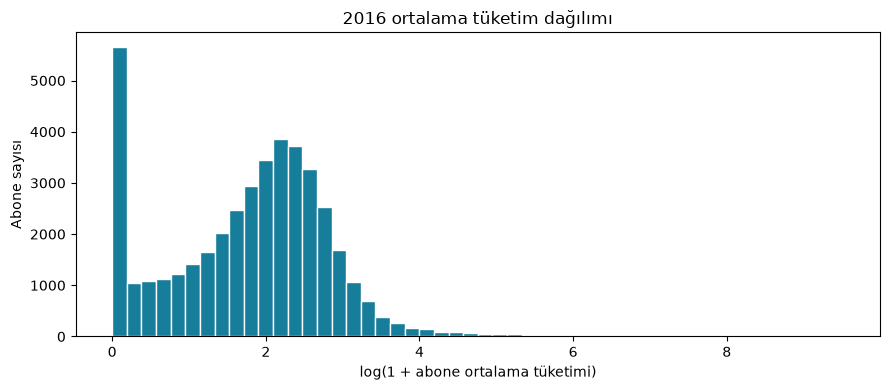

In [17]:
import numpy as np
plt.figure(figsize=(9, 4))
plt.hist(np.log1p(abone_ortalama_2016.dropna()), bins=50, color="#167D9A", edgecolor="white")
plt.xlabel("log(1 + abone ortalama tüketimi)")
plt.ylabel("Abone sayısı")
plt.title("2016 ortalama tüketim dağılımı")
plt.tight_layout()
plt.savefig(figur_klasoru / "01_tuketim_histogrami.png", dpi=150, bbox_inches="tight")
plt.show()

### 15. Yüzde 95–99 aralığındaki etiket ilişkisi

In [18]:
# Yuvarlanmamış gerçek sınırları hesaplıyoruz.
sinir_95 = abone_ortalama_2016.quantile(0.95)
sinir_99 = abone_ortalama_2016.quantile(0.99)

# Ortalaması bu sınırlar arasında olan aboneleri seçiyoruz.
aralik_secimi = (
    (abone_ortalama_2016 > sinir_95)
    & (abone_ortalama_2016 <= sinir_99)
)

# Bu abonelerin hazır FLAG etiketlerini alıyoruz.
grup_etiketleri = df.loc[aralik_secimi, "FLAG"]

# Karşılaştırma için 2016 ortalaması hesaplanabilen bütün aboneler.
gecerli_etiketler = df.loc[
    abone_ortalama_2016.notna(), "FLAG"
]

print("Seçilen gruptaki abone sayısı:", len(grup_etiketleri))
print("FLAG=0 abone sayısı:", (grup_etiketleri == 0).sum())
print("FLAG=1 abone sayısı:", (grup_etiketleri == 1).sum())

print(
    "\nSeçilen grupta kaçak etiketi oranı (%):",
    round((grup_etiketleri == 1).mean() * 100, 2)
)

print(
    "2016 ortalaması hesaplanabilen abonelerde kaçak etiketi oranı (%):",
    round((gecerli_etiketler == 1).mean() * 100, 2)
)

print(
    "Tüm veri setinde kaçak etiketi oranı (%):",
    round((df["FLAG"] == 1).mean() * 100, 2)
)

Seçilen gruptaki abone sayısı: 1693
FLAG=0 abone sayısı: 1229
FLAG=1 abone sayısı: 464

Seçilen grupta kaçak etiketi oranı (%): 27.41
2016 ortalaması hesaplanabilen abonelerde kaçak etiketi oranı (%): 8.46
Tüm veri setinde kaçak etiketi oranı (%): 8.53


### 16. En yüksek ortalamalı on abone

In [19]:
# 2016 tüketim ortalaması en yüksek olan 10 aboneyi seçiyoruz.
en_yuksek_10 = abone_ortalama_2016.nlargest(10).index

# Bu abonelerin 2016 tüketim kayıtları.
secili_tuketim = tum_2016.loc[en_yuksek_10]

# Ortalama, ortanca, en yüksek değer ve kayıt sayısını karşılaştırıyoruz.
yuksek_tuketim_ozeti = pd.DataFrame({
    "Abone kimliği": df.loc[en_yuksek_10, "CONS_NO"],
    "FLAG": df.loc[en_yuksek_10, "FLAG"],
    "Ortalama": secili_tuketim.mean(axis=1),
    "Ortanca": secili_tuketim.median(axis=1),
    "En yüksek günlük değer": secili_tuketim.max(axis=1),
    "Dolu gün sayısı": secili_tuketim.count(axis=1),
    "Eksik oranı (%)": secili_tuketim.isna().mean(axis=1) * 100
})

display(yuksek_tuketim_ozeti.round(2))

,Abone kimliği,FLAG,Ortalama,Ortanca,En yüksek günlük değer,Dolu gün sayısı,Eksik oranı (%)
1359,011FCB87987B5806AA1880B584FF0684,1,13601.10,14880.00,27180.0,300,1.32
2299,6FF9EEDA2593930830A1D5C5591016F0,1,5974.45,5958.00,7662.0,301,0.99
2123,D8D7BD1D4EA60D0ACFDE888654CB5FD9,1,3495.51,3732.00,6108.0,303,0.33
1451,FB0506FAED1441E1B46C95E150163594,1,3348.95,4027.00,5099.0,244,19.74
2498,0386CA5CC318BE77720EDBBEF445B58B,1,2804.23,3305.60,4348.0,291,4.28
2941,130F129A06DD299839553DD35D14B35A,1,2619.89,2450.00,4028.4,304,0.00
3544,3A23440EC3E239446F9A53B26D629E1C,1,1843.64,1992.00,4076.0,255,16.12
41043,2DE49E33C3BD179A052591BA0B9C3C39,0,1647.14,1779.90,2635.2,304,0.00
1897,97DAB9D2FB840E5D4A561E8BF390210D,1,1405.57,1417.35,2043.6,299,1.64
662,28A1DCF56B2B30F6C6849F2E36D1EC84,1,1128.55,902.00,3796.0,304,0.00


### 17. Sıfır gün oranı

In [20]:
# Her abonenin 2016 döneminde kaç dolu kaydı var?
dolu_gun = tum_2016.count(axis=1)

# Bu kayıtların kaçında tüketim sıfır?
sifir_gun = tum_2016.eq(0).sum(axis=1)

# Hiç kaydı olmayan abonelerde sıfıra bölmeyi önlüyoruz.
# Bu abonelerin oranı bilinmiyor olarak kalacak.
payda = dolu_gun.where(dolu_gun > 0)

# Yalnızca mevcut kayıtlar içindeki sıfır gün yüzdesi.
sifir_gun_yuzde = sifir_gun / payda * 100

# Özellik ile hazır etiketi inceleme amacıyla yan yana koyuyoruz.
sifir_inceleme = pd.DataFrame({
    "FLAG": df["FLAG"],
    "dolu_gun": dolu_gun,
    "sifir_gun": sifir_gun,
    "sifir_gun_yuzde": sifir_gun_yuzde
})

# İki sınıftaki sıfır gün oranlarını karşılaştırıyoruz.
sifir_ozet = sifir_inceleme.groupby("FLAG").agg(
    orani_hesaplanan_abone=("sifir_gun_yuzde", "count"),
    ortalama_sifir_gun_yuzdesi=("sifir_gun_yuzde", "mean"),
    ortanca_sifir_gun_yuzdesi=("sifir_gun_yuzde", "median")
)

display(sifir_ozet.round(2))

print(
    "Kayıt olmadığı için oranı hesaplanamayan abone:",
    sifir_gun_yuzde.isna().sum()
)

Kayıt olmadığı için oranı hesaplanamayan abone: 48


,orani_hesaplanan_abone,ortalama_sifir_gun_yuzdesi,ortanca_sifir_gun_yuzdesi
FLAG,,,
0,38744,18.02,0.0
1,3580,9.98,0.0


## Bulgular
Aşağıdaki bulgular bu veri sürümünün çıktılarıdır. “Henüz yapılmayanlar” 01 defterinin kapsamını ifade eder; hazırlık 02 defterinde devam eder.

## Bulgular ve İlk Değerlendirme

### 1. Veri setinin yapısı

GridLeak AI projesinde kullanılan veri seti, 42.372 aboneye ait
42.372 satır ve 1.036 sütundan oluşmaktadır.

- CONS_NO: Aboneyi tanımlayan kimlik alanıdır.
- FLAG: Modelin tahmin etmesi amaçlanan hedef etikettir.
- Kalan 1.034 sütun: Tarih bazlı günlük tüketim kayıtlarını içermektedir.

Abone kimliklerinde eksik değer veya tekrar tespit edilmemiştir.
Her satır farklı bir aboneye karşılık gelmektedir.

Tüketim sütunlarının tamamı sayısal veri türünde okunmuştur.
Ancak sayısal türde okunmaları, bütün değerlerin hatasız olduğunu
tek başına göstermemektedir.

### 2. Hedef değişken ve sınıf dağılımı

Veri setindeki hazır etiketlerin dağılımı şöyledir:

| Etiket | Açıklama | Abone sayısı | Oran |
|---|---|---:|---:|
| FLAG=0 | Kaçak olmayan olarak etiketlenmiş | 38.757 | %91,47 |
| FLAG=1 | Kaçak olarak etiketlenmiş | 3.615 | %8,53 |

Bu dağılım, sınıfların dengesiz olduğunu göstermektedir.

Tüm aboneleri FLAG=0 olarak tahmin eden bir model, kaçak etiketli
abonelerin hiçbirini yakalayamamasına rağmen yaklaşık %91,47 doğruluk
elde edebilir. Bu nedenle model değerlendirmesinde yalnızca doğruluk
kullanılmayacaktır. Precision, recall, F1 ve Average Precision gibi
ölçütler de incelenecektir.

FLAG, veri sağlayıcısının sunduğu hedef etikettir; bu çalışmada
üretilmiş bir tahmin değildir. Etiketlerin doğrulanma yöntemi
yalnızca CSV içeriğinden belirlenememektedir.

### 3. Tarih kapsamı ve eksik tarih sütunu

Tüketim sütunları 1 Ocak 2014 ile 31 Ekim 2016 arasındaki dönemi
kapsamaktadır. Dosyadaki sütun sırası doğrudan takvim sırasını
izlemediği için, analiz amacıyla ayrı bir tabloda tarihler
eskiden yeniye sıralanmıştır.

Bu iki tarih arasında 1.035 takvim günü bulunmasına rağmen
dosyada 1.034 tarih sütunu bulunmaktadır.

- Dosyada bulunmayan tarih: 18 Eylül 2016.
- Tekrarlanan tarih sütunu sayısı: 0.

Bu durum, mevcut sütunların içindeki boş hücrelerden farklıdır:
18 Eylül 2016 için dosyada bir sütun hiç bulunmamaktadır.
Bu tarihin neden eksik olduğu henüz bilinmemektedir.

### 4. Genel tüketim verisi kalitesi

Mevcut 1.034 tüketim sütununda toplam 43.812.648 hücre bulunmaktadır.

| Kontrol | Sonuç |
|---|---:|
| Toplam tüketim hücresi | 43.812.648 |
| Eksik tüketim hücresi | 11.233.528 |
| Eksik hücre oranı | %25,64 |
| Dolu tüketim hücresi, sıfırlar dahil | 32.579.120 |
| Sıfır değerli tüketim hücresi | 5.788.603 |
| Negatif tüketim hücresi | 0 |

Bütün abonelerin tüm dönem boyunca en az bir eksik tüketim
hücresi bulunmaktadır. Bu nedenle eksik kaydı bulunan bütün
abonelerin silinmesi, veri setinin tamamının kaybedilmesine yol açar.

Eksik değer ile sıfır tüketim ayrı değerlendirilmiştir:

- Eksik değer, ilgili günün tüketiminin veri setinde bilinmediğini gösterir.
- Sıfır değer, ilgili hücreye sıfır tüketim kaydedildiğini gösterir.
- Sıfır tüketim, tek başına kaçak kullanım kanıtı değildir.

%25,64 oranı yalnızca dosyada mevcut tüketim sütunlarındaki
boşlukları kapsamaktadır; tamamen bulunmayan tarih sütunu
bu hesaba dahil değildir.

### 5. Eksik kayıtların abonelere dağılımı

Her abone için eksik tüketim hücresi yüzdesi hesaplanmıştır.
Eksikliğin abonelere eşit dağılmadığı görülmüştür.

Histogramda yaklaşık 21 bin abonenin eksiklik oranının %10'dan az
olduğu görülmektedir. Bu sayı grafikten yaklaşık olarak okunmuştur.

Eksiklik oranı %70 dahil, %80 hariç olan grupta ise tam olarak
9.323 abone bulunmaktadır.

| Etiket | Bu gruptaki abone sayısı | Kendi sınıfındaki payı |
|---|---:|---:|
| FLAG=0 | 8.442 | %21,78 |
| FLAG=1 | 881 | %24,37 |

Bu grubun doğrudan çıkarılması, 881 kaçak etiketli örneğin de
kaybedilmesine neden olacaktır. Bu nedenle yüksek eksiklik
oranına dayanarak otomatik abone silme işlemi yapılmamıştır.

### 6. Yüksek eksiklik grubunun zaman içindeki yapısı

%70–80 eksikliği bulunan abonelerden beş örneğin kayıt düzeni
görselleştirilmiştir. Örneklerde başlangıç döneminde uzun boşluklar,
sonraki dönemde ise büyük ölçüde dolu kayıtlar görülmüştür.

Ardından bu gözlem grubun tamamında araştırılmıştır.
9.323 abonenin 9.244'ünde ilk dolu tüketim kaydının Ocak 2016'da
başladığı bulunmuştur. Bu, incelenen grubun yaklaşık %99,15'idir.

Bu sonuç, aboneliklerin kesin olarak Ocak 2016'da başladığını
göstermemektedir. Yalnızca veri setindeki ilk mevcut kaydın
bu ayda bulunduğunu göstermektedir.

### 7. Seçilen 9.244 abonenin 2016 dönemi

İlk kaydı Ocak 2016'da başlayan bu 9.244 abonenin,
Ocak–Ekim 2016 dönemindeki mevcut 304 tarih sütunu incelenmiştir.

| Kontrol | Sonuç |
|---|---:|
| İncelenen abone | 9.244 |
| İncelenen tarih sütunu | 304 |
| Dönemdeki eksik hücre oranı | %1,43 |
| Eksikliği %10'dan az olan abone | 8.890 |
| Hiç eksik hücresi olmayan abone | 5.377 |

Tüm geçmişte yüksek eksiklik gösteren bu grubun 2016 döneminde
büyük ölçüde dolu kayıtlara sahip olduğu görülmüştür.
Bu nedenle toplam eksiklik oranının tek başına kayıtların
kullanılamaz olduğuna karar vermek için yeterli olmadığı anlaşılmıştır.

### 8. Bütün abonelerin 2016 dönemi

2016 dönemi incelemesi, bütün 42.372 aboneyi kapsayacak şekilde
genişletilmiştir.

Mevcut 304 tarih sütununda genel eksik hücre oranı %1,62'dir.
Bu dönemde 24.878 abonenin hiçbir tüketim hücresi eksik değildir.

| Etiket | Abone sayısı | Ortalama eksik yüzdesi | Ortanca eksik yüzdesi | Eksiksiz abone |
|---|---:|---:|---:|---:|
| FLAG=0 | 38.757 | %1,43 | %0,00 | 23.093 |
| FLAG=1 | 3.615 | %3,62 | %0,33 | 1.785 |

2016 dönemi, ortak ve daha eksiksiz bir inceleme aralığı için
aday olarak belirlenmiştir. Ancak eğitimde yalnızca bu dönemin
kullanılmasına henüz karar verilmemiştir.

Kaçak etiketli sınıfta ortalama eksiklik daha yüksektir.
Bu ilişki, eksikliğin kaçak kullanımın nedeni veya kesin
göstergesi olduğunu kanıtlamamaktadır.

Yalnızca eksiksiz abonelerin tutulması durumunda 1.830 kaçak
etiketli abone dışarıda kalacaktır. Bu nedenle böyle bir
eleme kuralı uygulanmamıştır.

Bu bölümdeki eksiklik oranları, mevcut 304 tarih sütununa göre
hesaplanmıştır; dosyada bulunmayan 18 Eylül günü dahil değildir.

### 9. Abone başına ortalama tüketim

Her abonenin 2016 dönemindeki dolu tüketim kayıtlarının
ortalaması hesaplanmıştır. Boş hücreler ortalamaya katılmamış,
sıfır değerler dahil edilmiştir.

42.324 abone için ortalama hesaplanabilmiştir.
48 abonenin 2016 dönemindeki bütün tüketim hücreleri boş olduğu
için ortalaması hesaplanamamıştır. Bu abonelerin önceki
yıllarda da kayıtsız olduğu sonucu çıkarılmamıştır.

Abone ortalamalarının özeti şöyledir:

| İstatistik | Değer |
|---|---:|
| Hesaplanabilen abone sayısı | 42.324 |
| Abone ortalamalarının ortalaması | 10,45 |
| Standart sapma | 83,28 |
| En düşük değer | 0,00 |
| %25 yüzdelik | 1,77 |
| Ortanca, %50 | 5,94 |
| %75 yüzdelik | 10,96 |
| %95 yüzdelik | 24,65 |
| %99 yüzdelik | 76,65 |
| En yüksek değer | 13.601,10 |

Değerler iki ondalık basamağa yuvarlanmıştır.
Bu tablo tek tek günlük tüketimlerin değil, abone başına
hesaplanan tüketim ortalamalarının dağılımını göstermektedir.

Üst yüzdeliklerdeki ve maksimumdaki büyük değerler, dağılımın
yüksek tüketim yönünde uzadığını göstermektedir.
Bu değerler otomatik olarak hatalı veya kaçak kabul edilmemiştir.

### 10. Yüksek tüketim aralığı ile hedef etiketin ilişkisi

2016 tüketim ortalaması %95 yüzdelik sınırının üzerinde,
%99 yüzdelik sınırında veya altında kalan aboneler incelenmiştir.
Seçimde yuvarlanmamış gerçek sınırlar kullanılmıştır.

| Kontrol | Sonuç |
|---|---:|
| Seçilen abone sayısı | 1.693 |
| FLAG=0 abone sayısı | 1.229 |
| FLAG=1 abone sayısı | 464 |
| Seçilen gruptaki kaçak etiketi oranı | %27,41 |
| 2016 ortalaması hesaplanan abonelerde kaçak etiketi oranı | %8,46 |
| Tüm veri setindeki kaçak etiketi oranı | %8,53 |

Seçilen grubun kaçak etiketi oranı, 2016 ortalaması
hesaplanabilen abonelerin genel oranının yaklaşık 3,24 katıdır.

Bu bulgu, ortalama tüketimin ayırt edici bir özellik olabileceğini
göstermektedir. Ancak grubun çoğunluğu FLAG=0 olduğundan,
bu aralık tek başına kaçak kararı vermek için yeterli değildir.

%27,41, modelin ürettiği bir olasılık değil; mevcut kayıtlar
üzerinden hesaplanan grup içi etiket oranıdır.

### 11. En yüksek ortalamalı abonelerin incelenmesi

2016 tüketim ortalaması en yüksek olan 10 abone için ortalama,
ortanca, en yüksek günlük değer, dolu gün sayısı ve eksiklik
oranı birlikte incelenmiştir.

Bu 10 abonenin 9'u FLAG=1, biri FLAG=0 etiketlidir.
Bu, özellikle seçilmiş uç bir grubun gözlemidir;
bütün abonelere doğrudan genellenemez.

En yüksek ortalamaya sahip abonenin ortalaması 13.601,10,
ortancası 14.880,00 ve en yüksek günlük değeri 27.180,00'dır.
Bu abonenin 300 dolu günlük kaydı bulunmaktadır.

Ortancanın da yüksek olması, yüksek ortalamanın yalnızca
tek bir aşırı güne bağlı olmadığını göstermektedir.
Ancak bu durum, ölçümlerin doğruluğunu veya kullanımın
kaçak olup olmadığını tek başına belirlememektedir.

### 12. Sıfır tüketim günlerinin oranı

Her abonenin sıfır tüketim günleri, yalnızca dolu kayıtlarının
sayısına bölünerek yüzde hesaplanmıştır.

Boş günler sıfır tüketim sayılmamıştır.
2016 döneminde hiç dolu kaydı bulunmayan 48 abonenin
sıfır gün oranı bilinmeyen olarak bırakılmıştır.

| Etiket | Oranı hesaplanan abone | Ortalama sıfır gün yüzdesi | Ortanca sıfır gün yüzdesi |
|---|---:|---:|---:|
| FLAG=0 | 38.744 | %18,02 | %0,00 |
| FLAG=1 | 3.580 | %9,98 | %0,00 |

Bu veride, abone başına sıfır gün yüzdesinin ortalaması
kaçak olmayan etiketli grupta daha yüksektir.

Dolayısıyla “sıfır tüketim oranı yüksek olan abone kaçaktır”
şeklinde basit bir kural bulgularla desteklenmemektedir.
Sıfır gün oranı, diğer tüketim özellikleriyle birlikte
değerlendirilmelidir.

### 13. Bu aşamada yapılan ve yapılmayan işlemler

Yapılanlar:

- Veri dosyası okunmuş ve yapısı incelenmiştir.
- Kimlik, hedef ve tüketim alanları analiz amacıyla ayrılmıştır.
- Tarih sütunları ayrı bir tabloda takvim sırasına konulmuştur.
- Eksik, sıfır ve negatif değerler kontrol edilmiştir.
- Belirli abone grupları ve dönemler karşılaştırılmıştır.
- Ortalama tüketim ve sıfır gün oranı keşif amacıyla hesaplanmıştır.

Henüz yapılmayanlar:

- Orijinal CSV değiştirilmemiştir.
- Abone silinmemiştir.
- Eksik tüketim değerleri doldurulmamıştır.
- Eksik tarih sütunu eklenmemiştir.
- Eğitim/test ayrımı yapılmamıştır.
- Nihai dönem ve özellik listesi seçilmemiştir.
- Ölçekleme veya SMOTE uygulanmamıştır.
- Model eğitilmemiş ve model başarısı ölçülmemiştir.

### 14. Genel değerlendirme ve sonraki aşama

Eksikliklerin zaman içinde yoğunlaştığı ve 2016 döneminin
önceki dönemleri de içeren bütün geçmişe göre daha eksiksiz
olduğu belirlenmiştir. Bununla birlikte dönem seçimi,
veri kalitesi ile kullanılabilir geçmiş uzunluğu arasında
bir değerlendirme gerektirmektedir.

Yüksek tüketim, sıfır tüketim veya eksik kayıt tek başına
kesin kaçak göstergesi olarak kabul edilmemiştir.

Sonraki aşamada aboneler, sınıf oranlarını koruyacak şekilde
eğitim ve test gruplarına ayrılacaktır. Dönem, ön işleme,
özellik ve model seçenekleri eğitim verisi içinde
çapraz doğrulamayla karşılaştırılacaktır.

Doldurma ve ölçekleme gibi veriden öğrenilen dönüşümler,
her çapraz doğrulama adımında yalnızca ilgili eğitim
bölümüne göre öğrenilecektir. SMOTE kullanılacaksa yalnızca
eğitim bölümlerinde uygulanacaktır.

Bu ilk keşif tüm veri üzerinde yapıldığı için, sonradan
ayrılacak test grubu keşif aşamasından tamamen bağımsız
kabul edilemez. Bu sınırlılık raporda belirtilecek; bundan
sonraki yöntem ve model seçimlerinde test sonuçları
kullanılmayacaktır.

Projenin amacı kesin kaçak hükmü vermek değil, tüketim
örüntülerinden bir model skoru üretmek ve saha incelemesinin
önceliklendirilmesine yardımcı olmaktır. Veri kalitesi,
model skoru ve denetim önceliği ayrı bilgiler olarak
sunulacaktır.